# Logistic Regression: Student Performance Factors

## Step 1: Import Libraries

In [1]:
import pandas as pd, numpy as np
import matplotlib.pyplot as plt, seaborn as sns, joblib
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, confusion_matrix, classification_report,
                             roc_auc_score, roc_curve, ConfusionMatrixDisplay)

## Step 2: Load and Explore Data

In [3]:
df = pd.read_csv('StudentPerformanceFactors.csv')
print(df.shape)
df.head()

(6607, 20)


,Hours_Studied,Attendance,Parental_Involvement,Access_to_Resources,Extracurricular_Activities,Sleep_Hours,Previous_Scores,Motivation_Level,Internet_Access,Tutoring_Sessions,Family_Income,Teacher_Quality,School_Type,Peer_Influence,Physical_Activity,Learning_Disabilities,Parental_Education_Level,Distance_from_Home,Gender,Exam_Score
0,23,84,Low,High,No,7,73,Low,Yes,0,Low,Medium,Public,Positive,3,No,High School,Near,Male,67
1,19,64,Low,Medium,No,8,59,Low,Yes,2,Medium,Medium,Public,Negative,4,No,College,Moderate,Female,61
2,24,98,Medium,Medium,Yes,7,91,Medium,Yes,2,Medium,Medium,Public,Neutral,4,No,Postgraduate,Near,Male,74
3,29,89,Low,Medium,Yes,8,98,Medium,Yes,1,Medium,Medium,Public,Negative,4,No,High School,Moderate,Male,71
4,19,92,Medium,Medium,Yes,6,65,Medium,Yes,3,Medium,High,Public,Neutral,4,No,College,Near,Female,70


In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6607 entries, 0 to 6606
Data columns (total 20 columns):
 #   Column                      Non-Null Count  Dtype 
---  ------                      --------------  ----- 
 0   Hours_Studied               6607 non-null   int64 
 1   Attendance                  6607 non-null   int64 
 2   Parental_Involvement        6607 non-null   object
 3   Access_to_Resources         6607 non-null   object
 4   Extracurricular_Activities  6607 non-null   object
 5   Sleep_Hours                 6607 non-null   int64 
 6   Previous_Scores             6607 non-null   int64 
 7   Motivation_Level            6607 non-null   object
 8   Internet_Access             6607 non-null   object
 9   Tutoring_Sessions           6607 non-null   int64 
 10  Family_Income               6607 non-null   object
 11  Teacher_Quality             6529 non-null   object
 12  School_Type                 6607 non-null   object
 13  Peer_Influence              6607 non-null   obje

In [5]:
df.describe()

,Hours_Studied,Attendance,Sleep_Hours,Previous_Scores,Tutoring_Sessions,Physical_Activity,Exam_Score
count,6607.000000,6607.000000,6607.00000,6607.000000,6607.000000,6607.000000,6607.000000
mean,19.975329,79.977448,7.02906,75.070531,1.493719,2.967610,67.235659
std,5.990594,11.547475,1.46812,14.399784,1.230570,1.031231,3.890456
min,1.000000,60.000000,4.00000,50.000000,0.000000,0.000000,55.000000
25%,16.000000,70.000000,6.00000,63.000000,1.000000,2.000000,65.000000
50%,20.000000,80.000000,7.00000,75.000000,1.000000,3.000000,67.000000
75%,24.000000,90.000000,8.00000,88.000000,2.000000,4.000000,69.000000
max,44.000000,100.000000,10.00000,100.000000,8.000000,6.000000,101.000000


## Step 3: Data Cleaning

In [6]:
print(df.isnull().sum())
df = df.drop_duplicates()
df = df.dropna()
print(df.shape)

Hours_Studied                  0
Attendance                     0
Parental_Involvement           0
Access_to_Resources            0
Extracurricular_Activities     0
Sleep_Hours                    0
Previous_Scores                0
Motivation_Level               0
Internet_Access                0
Tutoring_Sessions              0
Family_Income                  0
Teacher_Quality               78
School_Type                    0
Peer_Influence                 0
Physical_Activity              0
Learning_Disabilities          0
Parental_Education_Level      90
Distance_from_Home            67
Gender                         0
Exam_Score                     0
dtype: int64
(6378, 20)


## Step 4: Create Binary Target (Pass = score >= 70)

0    4797
1    1581
Name: Result, dtype: int64


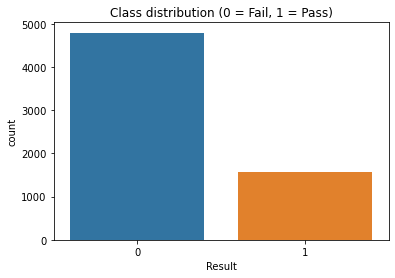

In [7]:
df['Result'] = (df['Exam_Score'] >= 70).astype(int)   # 1 = Pass, 0 = Fail
print(df['Result'].value_counts())
sns.countplot(x='Result', data=df)
plt.title('Class distribution (0 = Fail, 1 = Pass)')
plt.show()

## Select Features

In [ ]:
num_cols = ['Hours_Studied', 'Attendance', 'Previous_Scores',
            'Sleep_Hours', 'Tutoring_Sessions', 'Physical_Activity']
cat_cols = ['Parental_Involvement', 'Motivation_Level']

X = df[num_cols + cat_cols]
y = df['Result']

## Step 5: Split, Preprocess and Train

In [10]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)

preprocess = ColumnTransformer([
    ('num', StandardScaler(), num_cols),
    ('cat', OneHotEncoder(handle_unknown='ignore'), cat_cols)
])

model = Pipeline([
    ('prep', preprocess),
    ('lr', LogisticRegression(max_iter=1000, class_weight='balanced'))
])

model.fit(X_train, y_train)

Pipeline(steps=[('prep',
                 ColumnTransformer(transformers=[('num', StandardScaler(),
                                                  ['Hours_Studied',
                                                   'Attendance',
                                                   'Previous_Scores',
                                                   'Sleep_Hours',
                                                   'Tutoring_Sessions',
                                                   'Physical_Activity']),
                                                 ('cat',
                                                  OneHotEncoder(handle_unknown='ignore'),
                                                  ['Parental_Involvement',
                                                   'Motivation_Level'])])),
                ('lr',
                 LogisticRegression(class_weight='balanced', max_iter=1000))])

## Step 6: Model Evaluation

In [11]:
y_pred = model.predict(X_test)
y_prob = model.predict_proba(X_test)[:, 1]

print("Accuracy :", accuracy_score(y_test, y_pred))
print("ROC-AUC  :", roc_auc_score(y_test, y_prob))
print("\nClassification Report:\n", classification_report(y_test, y_pred, target_names=['Fail','Pass']))

Accuracy : 0.8730407523510971
ROC-AUC  : 0.9577037183544304

Classification Report:
               precision    recall  f1-score   support

        Fail       0.97      0.86      0.91       960
        Pass       0.68      0.91      0.78       316

    accuracy                           0.87      1276
   macro avg       0.82      0.89      0.85      1276
weighted avg       0.90      0.87      0.88      1276



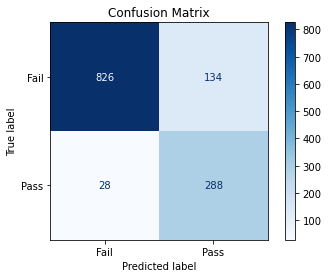

In [12]:
ConfusionMatrixDisplay(confusion_matrix(y_test, y_pred), display_labels=['Fail','Pass']).plot(cmap='Blues')
plt.title('Confusion Matrix')
plt.show()

## Step 7: Test One Prediction and Save the Model

In [14]:
sample = pd.DataFrame([{
    'Hours_Studied': 25, 'Attendance': 90, 'Previous_Scores': 80,
    'Sleep_Hours': 7, 'Tutoring_Sessions': 2, 'Physical_Activity': 3,
    'Parental_Involvement': 'High', 'Motivation_Level': 'High'}])
print("Prediction:", "Pass" if model.predict(sample)[0] == 1 else "Fail")
print("Probability of Pass:", model.predict_proba(sample)[0][1])

joblib.dump(model, 'student_model.pkl')
print("Model saved: student_model.pkl")

Prediction: Pass
Probability of Pass: 0.9908351764569926
Model saved: student_model.pkl
